# AmesValue: exploratory data analysis

I use the training subset to explore prices and property characteristics before comparing models. Run this notebook after `python -m src.data` and before `python -m src.train`. No rows are removed here.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Support launching Jupyter from either the project root or notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import load_data, split_data
from src.features import HouseFeatures
sns.set_theme(style="whitegrid")
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Keep the training split for this exploration.
X_train, _, y_train, _ = split_data(load_data())
X = HouseFeatures().fit_transform(X_train)
train = X.assign(SalePrice=y_train)
print(f"Training rows: {len(train)}; input features: {X.shape[1]}")
print("Numeric / categorical:", len(X.select_dtypes("number").columns),
      len(X.select_dtypes("object").columns))

Training rows: 1168; input features: 75
Numeric / categorical: 33 42


## 1. Sale prices

I compare the original and log-transformed price distributions. High prices stretch the right tail and pull the mean above the median. The model comparisons will check whether a log target improves predictions.

Skewness: 1.743128561420854


count      1168.000000
mean     181441.541952
std       77263.583862
min       34900.000000
25%      130000.000000
50%      165000.000000
75%      214925.000000
max      745000.000000
Name: SalePrice, dtype: float64

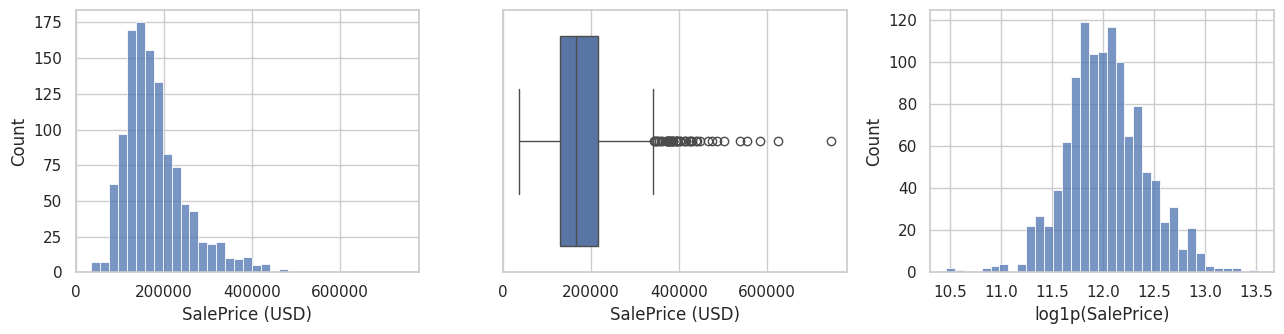

In [2]:
display(y_train.describe())
print("Skewness:", y_train.skew())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.histplot(y_train, bins=35, ax=axes[0])
sns.boxplot(x=y_train, ax=axes[1])
sns.histplot(np.log1p(y_train), bins=35, ax=axes[2])
axes[0].set_xlabel("SalePrice (USD)")
axes[1].set_xlabel("SalePrice (USD)")
axes[2].set_xlabel("log1p(SalePrice)")
fig.tight_layout()
fig.savefig(FIGURES / "eda_target.png", dpi=150)
plt.show()

## 2. Numeric features

These plots compare quality, living area, garage capacity, basement area and year built with sale price. `MSSubClass` is treated as a category; `OverallQual` remains an ordered numeric rating.

Correlations help describe linear relationships. They do not tell me what would happen to the price if a particular feature changed.

,count,mean,std,min,25%,50%,75%,max
LotFrontage,951.0,70.343849,24.897021,21.0,59.00,70.0,80.00,313.0
LotArea,1168.0,10689.642123,10759.366198,1300.0,7587.25,9600.0,11700.00,215245.0
OverallQual,1168.0,6.121575,1.367619,1.0,5.00,6.0,7.00,10.0
OverallCond,1168.0,5.584760,1.116062,1.0,5.00,5.0,6.00,9.0
YearBuilt,1168.0,1970.965753,30.675495,1872.0,1953.00,1972.0,2001.00,2010.0
YearRemodAdd,1168.0,1984.897260,20.733955,1950.0,1966.00,1994.0,2004.00,2010.0
MasVnrArea,1162.0,103.771945,173.032238,0.0,0.00,0.0,166.00,1378.0
BsmtFinSF1,1168.0,446.023973,459.070977,0.0,0.00,384.5,721.00,5644.0
BsmtFinSF2,1168.0,45.152397,158.217499,0.0,0.00,0.0,0.00,1127.0
BsmtUnfSF,1168.0,570.595034,446.364551,0.0,222.50,480.0,810.25,2336.0


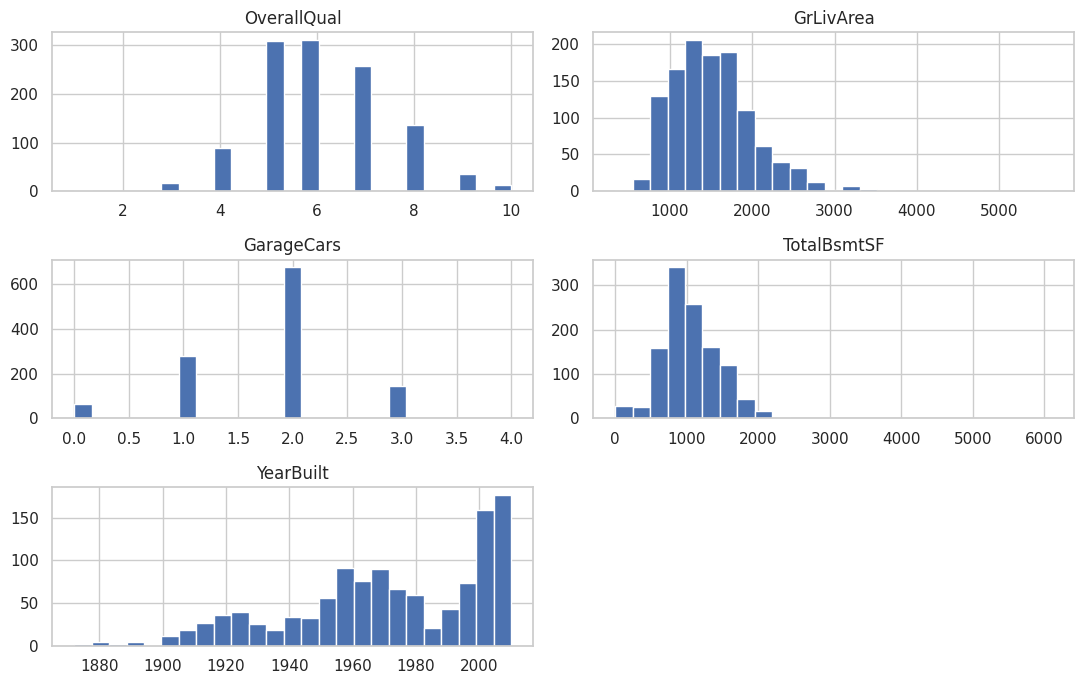

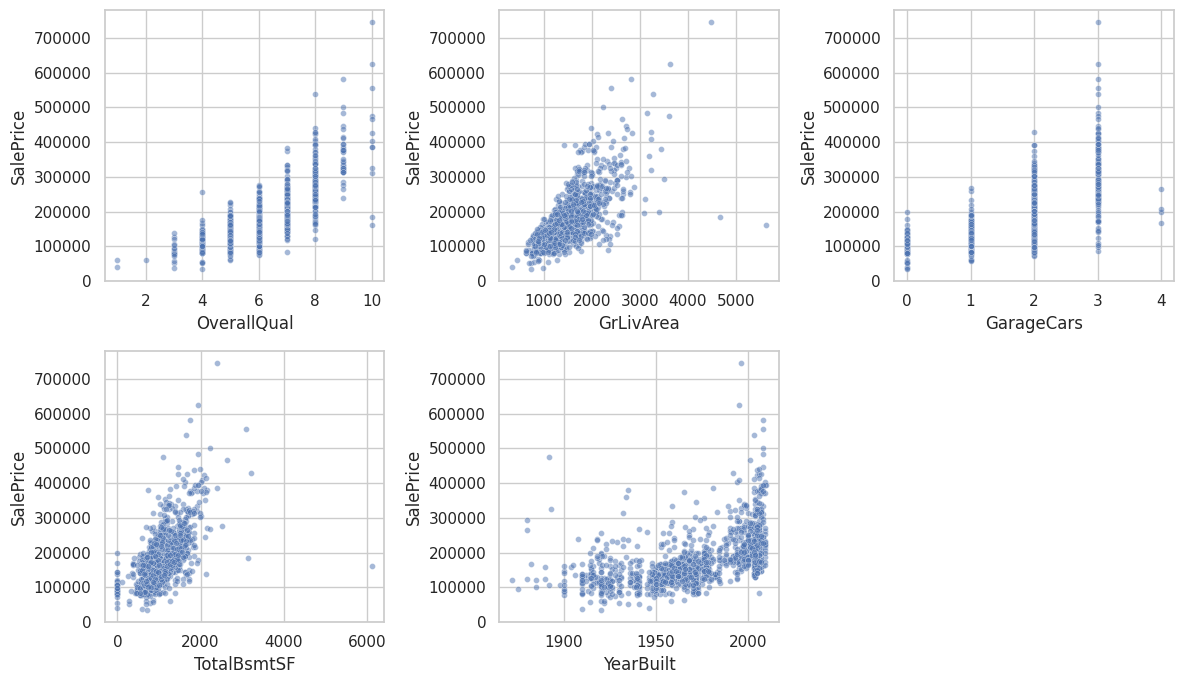

,Correlation with SalePrice
OverallQual,0.785555
GrLivArea,0.695652
GarageCars,0.640991
GarageArea,0.624139
TotalBsmtSF,0.597766
1stFlrSF,0.587883
FullBath,0.552546
TotRmsAbvGrd,0.520388
YearBuilt,0.516501
YearRemodAdd,0.508593


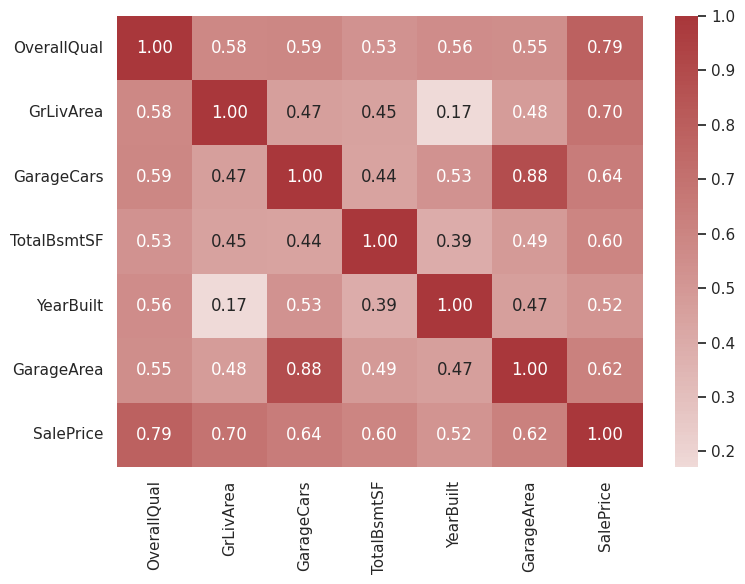

In [3]:
numeric = X.select_dtypes("number")
display(numeric.describe().T)
selected = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt"]
numeric[selected].hist(bins=25, figsize=(11, 7))
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for feature, ax in zip(selected, axes.flat):
    sns.scatterplot(data=train, x=feature, y="SalePrice", alpha=0.5, s=18, ax=ax)
axes.flat[-1].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_relationships.png", dpi=150)
plt.show()

correlations = numeric.corrwith(y_train).sort_values(ascending=False)
display(correlations.to_frame("Correlation with SalePrice"))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(train[selected + ["GarageArea", "SalePrice"]].corr(),
            annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
fig.tight_layout()
plt.show()

## 3. Categorical features

I compare prices across neighborhoods, exterior-quality ratings and building types. Counts matter here: a median based on a small group is less informative. Differences also reflect other property characteristics, such as size and age.

,Count
Neighborhood,
NAmes,181
CollgCr,115
OldTown,91
Edwards,87
Somerst,69
NWAmes,66
Gilbert,65
NridgHt,61
Sawyer,58


,count,median,mean
Neighborhood,,,
MeadowV,10,89500.0,101890.000000
BrDale,13,100000.0,100915.384615
IDOTRR,26,108950.0,106623.076923
BrkSide,45,120000.0,122640.000000
Edwards,87,123500.0,127908.850575
Blueste,1,124000.0,124000.000000
OldTown,91,124000.0,132886.901099
Sawyer,58,134950.0,136867.810345
SWISU,21,139500.0,144823.047619


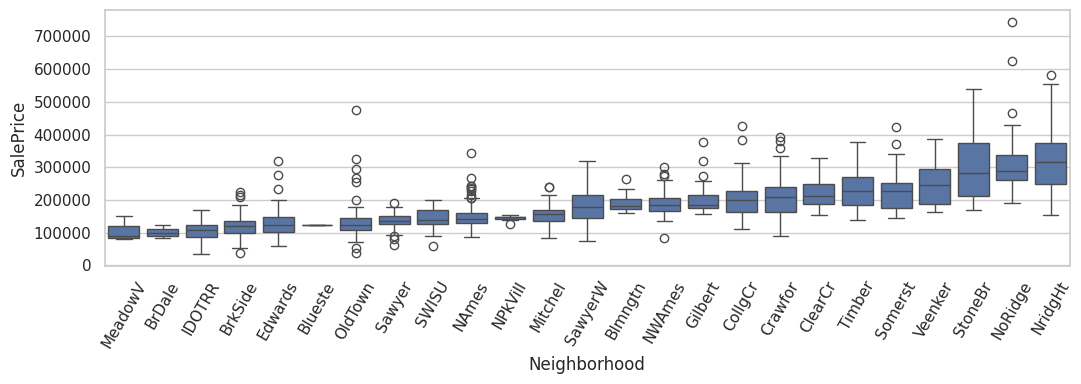

,Count
ExterQual,
TA,727
Gd,388
Ex,42
Fa,11


,count,median,mean
ExterQual,,,
Fa,11,85000.0,94072.727273
TA,727,140000.0,146536.671252
Gd,388,220500.0,230836.077320
Ex,42,353459.5,352199.119048


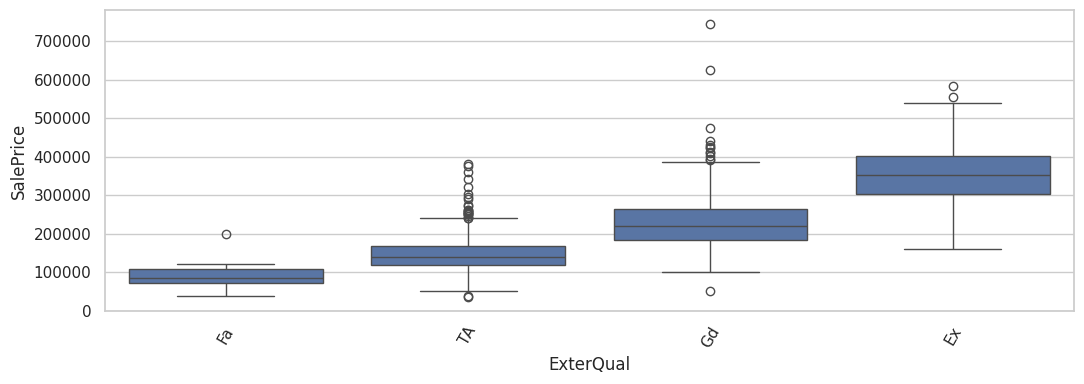

,Count
BldgType,
1Fam,978
TwnhsE,88
Duplex,41
Twnhs,32
2fmCon,29


,count,median,mean
BldgType,,,
2fmCon,29,127500.0,128582.758621
Duplex,41,136905.0,135883.390244
Twnhs,32,138700.0,136709.375000
1Fam,978,169500.0,186133.610429
TwnhsE,88,173116.5,184207.170455


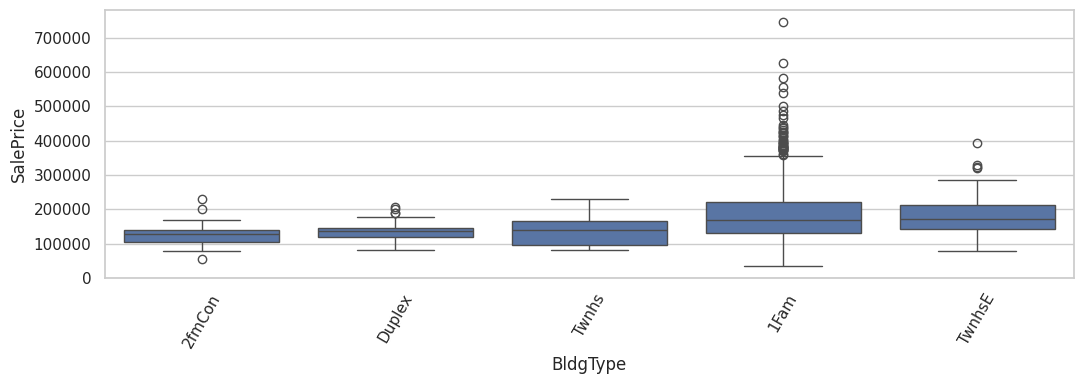

In [4]:
for feature in ["Neighborhood", "ExterQual", "BldgType"]:
    display(X[feature].value_counts(dropna=False).to_frame("Count"))
    summary = train.groupby(feature, observed=True).SalePrice.agg(["count", "median", "mean"])
    display(summary.sort_values("median"))
    fig, ax = plt.subplots(figsize=(11, 4))
    order = summary.sort_values("median").index
    sns.boxplot(data=train, x=feature, y="SalePrice", order=order, ax=ax)
    ax.tick_params(axis="x", rotation=60)
    fig.tight_layout()
    plt.show()

## 4. Missing values

Some missing garage or basement fields may mean that the facility is absent. I compare missing quality ratings with garage capacity and basement area below.

The pipeline keeps a `Missing_or_absent` category and imputes numeric values with training-fold medians. This is a simple approach, but it does not fully distinguish structural absence from unknown information.

In [5]:
missing = pd.DataFrame({"Count": X.isna().sum(), "Percent": 100 * X.isna().mean()})
display(missing[missing.Count > 0].sort_values("Percent", ascending=False))
for category, quantity in [("GarageQual", "GarageCars"), ("BsmtQual", "TotalBsmtSF")]:
    print(category, "missing: corresponding", quantity)
    display(X.loc[X[category].isna(), quantity].value_counts(dropna=False).head(10))

GarageQual missing: corresponding GarageCars
BsmtQual missing: corresponding TotalBsmtSF


,Count,Percent
PoolQC,1162,99.486301
MiscFeature,1122,96.061644
Alley,1094,93.664384
Fence,935,80.051370
FireplaceQu,547,46.832192
LotFrontage,217,18.578767
GarageCond,64,5.479452
GarageType,64,5.479452
GarageYrBlt,64,5.479452
GarageFinish,64,5.479452


GarageCars
0    64
Name: count, dtype: int64

TotalBsmtSF
0    28
Name: count, dtype: int64

## 5. Unusually large houses

I use the upper IQR threshold to inspect large living areas. A flagged house is not necessarily a recording error, so these rows stay in the dataset.

In [6]:
q1, q3 = X.GrLivArea.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
flagged = train.loc[X.GrLivArea > upper, ["GrLivArea", "OverallQual", "TotalBsmtSF", "SalePrice"]]
print("Living-area upper IQR threshold:", upper, "sq ft; flagged rows:", len(flagged))
display(flagged.sort_values("GrLivArea", ascending=False).head(10))
# Inspect the largest properties without removing rows.
print("Rows removed: 0")

Living-area upper IQR threshold: 2761.375 sq ft; flagged rows: 23
Rows removed: 0


,GrLivArea,OverallQual,TotalBsmtSF,SalePrice
1298,5642,10,6110,160000
523,4676,10,3138,184750
1182,4476,10,2396,745000
1169,3627,10,1930,625000
185,3608,10,1107,475000
304,3493,7,1470,295000
1268,3447,8,728,381000
635,3395,6,1440,200000
769,3279,8,1650,538000
1353,3238,8,2033,410000


## 6. Findings

- Training prices have a mean of **$181,442**, a median of **$165,000**, and skewness of **1.74**. A log target is worth comparing with the original prices.
- Overall quality and above-ground living area correlate with price at approximately **0.79** and **0.70**. Garage capacity and basement area also show positive relationships.
- Category price distributions differ but overlap. The pipeline will one-hot encode these features.
- Missing facility information needs to be retained rather than dropping the affected columns.
- Unusual area/price combinations deserve inspection, but I do not have evidence that they are errors. All observations remain.

The next step is to compare the median baseline and four regression models on identical folds, followed by log-target and bathroom/porch feature experiments. These choices are informed by the training data, so the CV results are development estimates. The separate test set is reserved for final evaluation.

Source: [OpenML 42165](https://www.openml.org/d/42165).